In [1]:
%%capture
!pip install rdkit

In [7]:
import pandas as pd
import numpy as np

from rdkit import Chem
from rdkit.Chem import Draw, PandasTools
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem
from rdkit import DataStructs
from rdkit.Chem.rdmolops import PatternFingerprint


from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
from sklearn.model_selection import train_test_split,KFold,cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder,LabelEncoder, MinMaxScaler

import pickle
import os
import random

In [3]:
seed = 76
os.environ['PYTHONHASHSEED'] = str(seed)
random.seed(seed)
np.random.seed(seed)

In [4]:
def compute_standardized_matrix(train_df, val_df, test_df):
    """
    Standardize train, validation, and test descriptors using the training set statistics.
    """
    mean_train = train_df.mean()
    std_train = train_df.std(ddof=0)  # population std

    standardized_train = (train_df - mean_train) / std_train
    standardized_val = (val_df - mean_train) / std_train
    standardized_test = (test_df - mean_train) / std_train

    return standardized_train, standardized_val, standardized_test

def compute_AD_details(standardized_df, threshold=3.0):
    """
    Compute AD flag and Snew for each compound.
    Returns a DataFrame with 'AD_Flag' and 'Snew'.
    """
    max_s = standardized_df.abs().max(axis=1)
    min_s = standardized_df.abs().min(axis=1)
    mean_s = standardized_df.abs().mean(axis=1)
    std_s = standardized_df.abs().std(axis=1, ddof=0)

    s_new = mean_s + 1.28 * std_s
    ad_flag = []

    for i in standardized_df.index:
        if max_s[i] <= threshold:
            ad_flag.append(1)
        elif min_s[i] > threshold:
            ad_flag.append(0)
        else:
            if s_new[i] <= threshold:
                ad_flag.append(1)
            else:
                ad_flag.append(0)

    return pd.DataFrame({
        "Snew": s_new,
        "AD_Flag": ad_flag
    }, index=standardized_df.index)

In [5]:
df = pd.read_excel('data.xlsx')

In [8]:
with open('train_ids.pkl', 'rb') as f:
    train_ids = pickle.load(f)


with open('val_ids.pkl', 'rb') as f:
    val_ids = pickle.load(f)

with open('test_ids.pkl', 'rb') as f:
    test_ids = pickle.load(f)

Train = df[df['ID'].isin(train_ids)].set_index('ID').loc[train_ids].reset_index()
Val = df[df['ID'].isin(val_ids)].set_index('ID').loc[val_ids].reset_index()
Test = df[df['ID'].isin(test_ids)]

In [12]:
# Combine Train and test
DF_raw = pd.concat([Train,Val, Test],ignore_index=True)
DF_data = DF_raw.copy()

In [16]:
DF_data.head(2)

,ID,TYPE,NICS(0),Can SMILES,ABC,nAcid,nBase,SpMAD_A,nAromAtom,nBridgehead,...,bpol,n7Ring,nHRing,n6HRing,n5ARing,nAHRing,SLogP,JGI5,JGI6,TSRW10
0,A252,Substituted Hetero Six-Membered Ring,-8.16,Nc1ccc([NH3+])cc1,5.875634,0,1,1.240597,6,0,...,7.318863,0,0,0,0,0,0.1422,0.0,0.0,35.730685
1,A300,Monoprotonated Borapyridine,-5.06,b1bc[nH+]cb1,4.242641,0,1,1.333333,6,0,...,6.299621,0,1,1,0,0,-1.4850,0.0,0.0,30.941317


In [15]:
DF_data.shape

(503, 193)

In [18]:
DF_data = DF_data[['nB', 'Xch-5d', 'n6HRing', 'n7Ring', 'ATSC3s', 'ETA_beta_ns_d',
                   'ATSC4v', 'BCUTZ-1l', 'nHRing', 'VSA_EState6', 'bpol', 'TSRW10',
                   'NaaCH', 'AMID', 'IC0']]

In [19]:
train_df = DF_data.iloc[:402, :]
val_df = DF_data.iloc[402:452, :]
test_df = DF_data.iloc[452:,:]

In [20]:
val_df.head(2)

,nB,Xch-5d,n6HRing,n7Ring,ATSC3s,ETA_beta_ns_d,ATSC4v,BCUTZ-1l,nHRing,VSA_EState6,bpol,TSRW10,NaaCH,AMID,IC0
402,0,0.0,0,0,3.056049,0.0,-38.631331,5.656841,0,9.369630,5.016035,35.247635,5,1.961583,0.961237
403,0,0.0,1,0,-0.640955,0.0,69.487581,2.995958,1,3.946759,27.812828,33.544698,4,1.953832,1.676737


In [21]:
# Step 1: Standardize
standardized_train, standardized_val, standardized_test = compute_standardized_matrix(train_df, val_df, test_df)

# Step 2: Compute AD details (including Snew)
train_ad_info = compute_AD_details(standardized_train)
val_ad_info = compute_AD_details(standardized_val)
test_ad_info = compute_AD_details(standardized_test)

# Step 3: Add AD data to your original datasets
train_df_with_ad = train_df.copy()
val_df_with_ad = val_df.copy()
test_df_with_ad = test_df.copy()

train_df_with_ad["Snew"] = train_ad_info["Snew"]
train_df_with_ad["AD_Flag"] = train_ad_info["AD_Flag"]

val_df_with_ad["Snew"] = val_ad_info["Snew"]
val_df_with_ad["AD_Flag"] = val_ad_info["AD_Flag"]

test_df_with_ad["Snew"] = test_ad_info["Snew"]
test_df_with_ad["AD_Flag"] = test_ad_info["AD_Flag"]


In [22]:
test_df_with_ad.head(2)

,nB,Xch-5d,n6HRing,n7Ring,ATSC3s,ETA_beta_ns_d,ATSC4v,BCUTZ-1l,nHRing,VSA_EState6,bpol,TSRW10,NaaCH,AMID,IC0,Snew,AD_Flag
452,0,0.176777,0,0,-2.206790,0.0,156.766852,5.780057,1,1.833333,4.582828,41.004802,3,1.9375,1.530493,1.145647,1
453,0,0.176777,0,0,-2.341837,0.0,0.000000,5.956200,1,0.000000,2.576414,41.004802,1,1.9375,1.378783,1.299320,1


In [23]:
train_df_flags = pd.concat([train_df_with_ad, DF_raw.iloc[:len(Train), :5]], axis=1)
val_df_flags = pd.concat([val_df_with_ad, DF_raw.iloc[402:452, :5]], axis=1).reset_index(drop=True)
test_df_flags = pd.concat([test_df_with_ad, DF_raw.iloc[452:, :5]], axis=1).reset_index(drop=True)

train_df_flags['Snew'] = train_df_flags['Snew'].map('{:.2f}'.format)
val_df_flags['Snew'] = val_df_flags['Snew'].map('{:.2f}'.format)
test_df_flags['Snew'] = test_df_flags['Snew'].map('{:.2f}'.format)

In [27]:
# train compounds outside AD (AD_Flag=0)
train_df_flags[train_df_flags['AD_Flag']==0].shape

(19, 22)

In [29]:
# val compounds outside AD (AD_Flag=0)
val_df_flags[val_df_flags['AD_Flag']==0].shape

(0, 22)

In [28]:
# test compounds outside AD (AD_Flag=0)
test_df_flags[test_df_flags['AD_Flag']==0].shape

(0, 22)

In [41]:
outside_ad = train_df_flags[train_df_flags['Snew'].astype('float') >= 3.0]

In [42]:
outside_ad.shape

(19, 22)

In [47]:
outside_ad = outside_ad.sort_values(by = 'Snew', ascending=True)

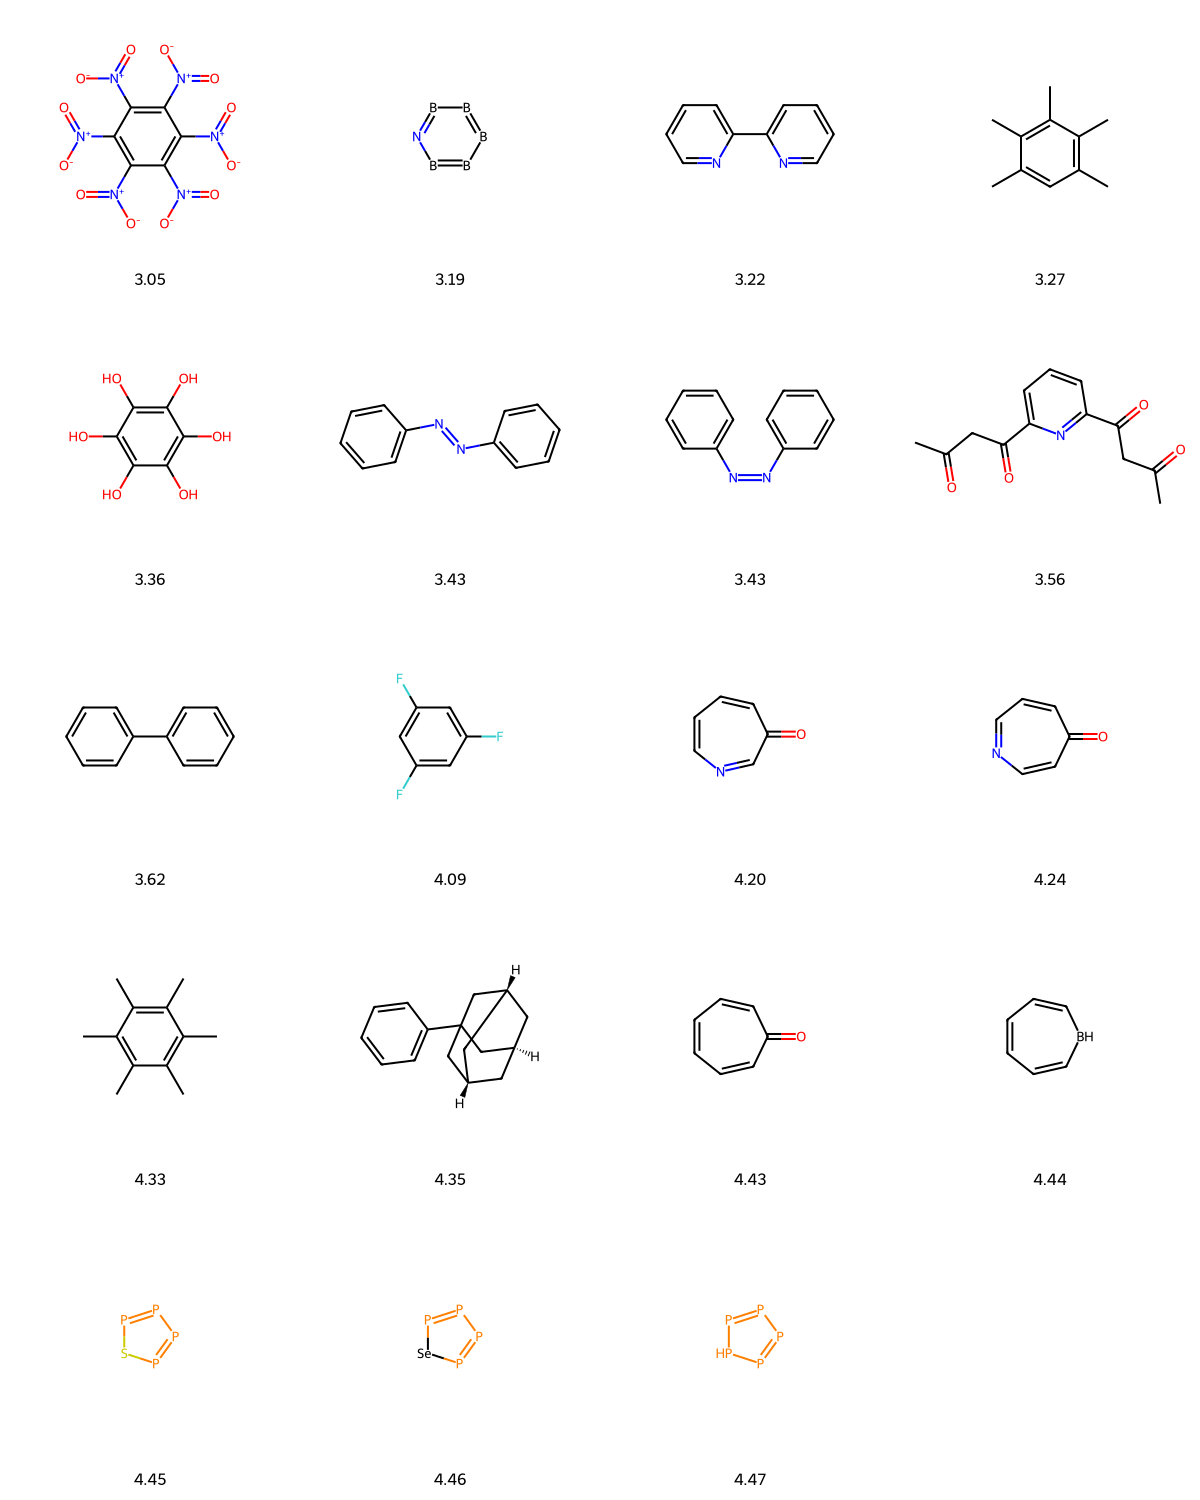

In [48]:
mols = [Chem.MolFromSmiles(smi) for smi in outside_ad['Can SMILES']]

Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(300, 300), legends = [str(x) for x in outside_ad['Snew']])